# 8.2 — Linear Regression Gradient Descent

**Chapter 8, section 8.2.3**, and the starting point for **Exercise 9**.

**The question this notebook answers:** what changes when the model has more than one parameter,
and what decides whether a given learning rate works?

The answer to the first is: almost nothing. Scalar multiplication becomes a dot product, the
accumulated gradient becomes a vector, and the loop is otherwise the loop of 8.1. The answer to
the second is the point of the last section: **the learning rate that works is a property of the
scale of the features, not of the algorithm.** The same loop that converges on features in
$[0,1]$ diverges on the same data multiplied by one hundred.

Source: `Notebooks old/Spark-Example-18-Linear-Regression-Gradient Descent.ipynb`.

> **A note for anyone editing this notebook.** The numbers printed in section 5 are quoted
> verbatim in the chapter. They are reproducible only because the generator is seeded once, in
> section 1, and every later cell draws from that stream in a fixed order. Adding, removing, or
> reordering a `np.random` call anywhere above section 6 changes all of them.

In [1]:
# --- CS-777 session setup ------------------------------------------------
import os, tempfile
import numpy as np
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession

SCRATCH = os.environ.get("CS777_SCRATCH", os.path.join(tempfile.gettempdir(), "cs777"))
os.makedirs(SCRATCH, exist_ok=True)

spark = (SparkSession.builder
         .appName("CS777-8.2")
         .master("local[4]")
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.sql.warehouse.dir", os.path.join(SCRATCH, "warehouse"))
         .getOrCreate())
sc = spark.sparkContext
sc.setLogLevel("ERROR")

print("Spark", spark.version)

Spark 4.2.0


---

## 1. Gradient descent in plain Python first

Before the distributed version, the same algorithm in one process, so that the distributed one has
something to be compared against. Two input variables, no intercept.

In [2]:
size = 1000
np.random.seed(100)  # seed for reproducibility; see the note at the top of this notebook
x1 = np.random.rand(size)
x2 = np.random.rand(size)
theta0 = 0
theta1 = 1
theta2 = 4
x = []
for i in range(size):
    x.append(np.array([x1[i], x2[i]]))
e = np.random.rand(size) * 0.2
y = theta0 + theta1 * x1 + theta2 * x2 + e

The two predictors and the response, plotted as a surface of points. The generating relationship
is a plane, and the noise is the thickness of the cloud around it.

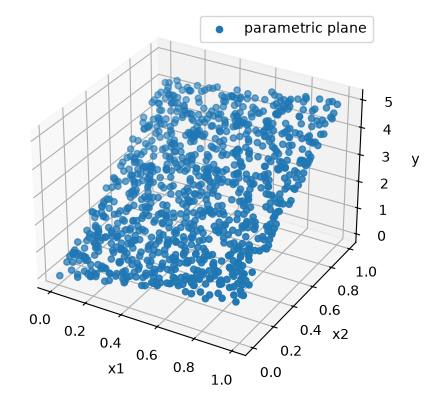

In [3]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter3D(x1, x2, y, label='parametric plane')
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_zlabel("y")
ax.legend()
plt.show()

The loop below is the sequential form of everything that follows. The inner `for` over the
training examples is the part that becomes a `map` and a `reduce`; the rest stays on the driver
unchanged.

In [4]:
learningRate = 1
num_iteration = 100
m_current = np.zeros(2)
n = float(size)

for i in range(num_iteration):
    cost = 0
    m_gradient = 0
    for j in range(size):
        y_prediction = np.dot(m_current, x[j])
        cost += (y[j] - y_prediction) ** 2       # monitoring only
        m_gradient += x[j] * (y[j] - y_prediction)
    m_gradient = (-1.0 / n) * m_gradient
    m_current = m_current - learningRate * m_gradient
    if i % 10 == 0 or i == num_iteration - 1:
        print(i, "m=", m_current, " Cost=", cost / n)

print("\ngenerated from theta = [1, 4]; recovered", m_current)

0 m= [1.33043523 1.53416632]  Cost= 7.722486846224706
10 m= [1.6647198 3.4849997]  Cost= 0.075756466820505
20 m= [1.3241708  3.83982464]  Cost= 0.017176233414348496
30 m= [1.18144617 3.98826633]  Cost= 0.0069060746418950995
40 m= [1.12168566 4.05042057]  Cost= 0.005105515640315622
50 m= [1.09666323 4.07644528]  Cost= 0.004789842553850977
60 m= [1.08618605 4.08734213]  Cost= 0.00473449890922133
70 m= [1.08179913 4.09190477]  Cost= 0.004724796089651895
80 m= [1.07996228 4.0938152 ]  Cost= 0.004723094996270233
90 m= [1.07919316 4.09461512]  Cost= 0.004722796761445567
99 m= [1.07889223 4.09492811]  Cost= 0.004722746589165424

generated from theta = [1, 4]; recovered [1.07889223 4.09492811]


---

## 2. The model, with many parameters

The linear model without an intercept, for $d$ predictors:

$$
y = \theta_1x_1 + \theta_2x_2 + \theta_3x_3
$$

The cost function is the mean squared error:

$$
L(\theta) = \frac{1}{2n} \sum_{i=1}^{n} \left(y_i - \theta^T x_i\right)^2
$$

and its gradient with respect to the whole parameter vector is

$$
\frac{\partial L}{\partial \theta} = \frac{-1}{n} \sum_{i=1}^{n} x_i \left(y_i - \theta^T x_i\right).
$$

Two things about this expression matter for the distributed implementation. It is a **sum over
independent per-example terms**, so it decomposes across partitions. And each term is a
**feature vector multiplied by a scalar residual**, so the arithmetic inside the `map` is one dot
product, one subtraction, and one scaling.

---

## 3. The data, and what `scale_x` does to it

`scale_x` multiplies the range of the input features. It is set to $1$ here, so the features lie
in $[0,1]$. **Section 6 sets it to $100$ and changes nothing else**, which is the experiment
Exercise 9(c) asks for.

In [5]:
# Data set parameters
size = 100        # number of observations
scale_x = 1       # scaling of the input features (default range is [0, 1])
d = 3             # number of features
theta = [-1, 1, 2]  # the parameters the data is generated from
error_rate = 0.1

x = np.random.rand(size, d)
x = x * scale_x
e = np.random.rand(size) * scale_x * error_rate

data = []
for i in range(size):
    y_i = np.dot(theta, x[i]) + e[i]
    data.append((y_i, x[i]))   # (target, feature vector)

myRDD = sc.parallelize(data)
myRDD.cache()
myRDD.take(3)

[(np.float64(1.3464109036658622), array([0.07673546, 0.56891249, 0.40011815])),
 (np.float64(1.1524787408949344), array([0.30889787, 0.92840502, 0.23497769])),
 (np.float64(1.2624236920576661), array([0.90186889, 0.84390848, 0.6279512 ]))]

Each record is a pair: the response, and a NumPy array holding the whole feature vector. That is
the record shape every implementation in this chapter uses.

The loop below is 8.1's loop with two changes. The intermediate values are now vectors, so
`x[0] * x[1]` multiplies a feature vector by a scalar residual rather than two scalars; and the
number of parameters is **inferred from the data** rather than written down, so the same routine
works whatever the feature count.

In [6]:
learningRate = 2
num_iteration = 10

d_input = len(myRDD.first()[1])            # infer the parameter count from the data
theta = np.zeros(d_input)
print(f"Input dimensionality is {d_input} and we start with {theta} as parameters")

for i in range(num_iteration):
    gradientAndCost = myRDD.map(lambda x: (x[1], (x[0] - np.dot(x[1], theta))))\
                           .map(lambda x: (x[0] * x[1], x[1]**2))\
                           .reduce(lambda x, y: (x[0] + y[0], x[1] + y[1]))
    cost = gradientAndCost[1] / (2 * size)
    gradient = (-1 / float(size)) * gradientAndCost[0]
    theta = theta - learningRate * gradient
    print(f"{i} Cost={cost:.5f} theta={theta}")

Input dimensionality is 3 and we start with [0. 0. 0.] as parameters
0 Cost=0.84789 theta=[0.94043852 1.22321453 1.49992073]
1 Cost=0.49769 theta=[-0.22786875  0.39484459  0.75476992]
2 Cost=0.29423 theta=[0.26378347 1.08819667 1.6187498 ]
3 Cost=0.17533 theta=[-0.41781334  0.63268725  1.22248715]
4 Cost=0.10539 theta=[-0.16602041  1.02699163  1.72238399]
5 Cost=0.06395 theta=[-0.5662644   0.77772352  1.51438187]


6 Cost=0.03922 theta=[-0.44109854  1.00284882  1.80506376]
7 Cost=0.02435 theta=[-0.67781049  0.86729915  1.69779029]
8 Cost=0.01532 theta=[-0.61838487  0.99643848  1.86774676]
9 Cost=0.00979 theta=[-0.75946414  0.92333691  1.81377695]


One detail of this loop is worth naming because it is where a reader's mental model of Spark
usually breaks. The lambda passed to `map` refers to `theta`, which is an ordinary Python variable
on the **driver**. At the start of each iteration Spark serializes the current value of `theta`
along with the function and ships a copy to every task. Every task therefore evaluates the
gradient at the same parameter values, and the update happens only on the driver, after the
reduction returns. There is no mutable state shared across the cluster.

---

## 4. Folding the intercept into the feature vector

With an intercept the model is

$$
y = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + \theta_3 x_3
$$

and the derivative with respect to $\theta_0$ has no feature value multiplying it, which would
need its own line of code. Prepending a constant $1$ to every feature vector removes the special
case: with

$$
X_i = (1, x_1, x_2, x_3), \qquad \theta = (\theta_0, \theta_1, \theta_2, \theta_3)
$$

the cost becomes $L(\theta) = \frac{1}{2n} \sum_i (y_i - \theta^T X_i)^2$ and the gradient becomes

$$
\frac{\partial L}{\partial \theta} = \frac{-1}{n} \sum_{i=1}^{n} X_i \left(y_i - \theta^T X_i\right),
$$

which is exactly the expression the previous loop already computes. The intercept is estimated by
the same update rule as every other coefficient, and the loop does not change at all.

In [7]:
# Data set parameters
size = 10000      # number of observations
scale_x = 1       # scaling of the input features
d = 3             # number of features
theta = [-1, 1, 2]  # the coefficients the data is generated from
theta0 = 5        # the intercept
error_rate = 0.1

x = np.random.rand(size, d)
x = x * scale_x
e = np.random.rand(size) * scale_x * error_rate

data = []
for i in range(size):
    y_i = np.dot(theta, x[i]) + theta0 + e[i]
    data.append((y_i, x[i]))

myRDD = sc.parallelize(data)
myRDD = myRDD.map(lambda x: (x[0], np.append(1, x[1])))   # fold in the intercept
myRDD.cache()
myRDD.take(3)

[(np.float64(6.030185391231586),
  array([1.        , 0.33354469, 0.04504392, 0.63766575])),
 (np.float64(6.3077513128698275),
  array([1.        , 0.2033653 , 0.07699913, 0.71496958])),
 (np.float64(5.332591792743148),
  array([1.        , 0.10727881, 0.16102717, 0.1206529 ]))]

---

## 5. Reading the printed cost

The same loop, on the intercept-augmented data, at a learning rate of $1$ for ten iterations.
**The trace this produces is the one quoted in the chapter.**

In [8]:
learningRate = 1
num_iteration = 10

d_input = len(myRDD.first()[1])
theta = np.zeros(d_input)
print(f"Input dimensionality is {d_input} and we start with {theta} as parameters ")

myRDD.cache()
for i in range(num_iteration):
    gradientAndCost = myRDD.map(lambda x: (x[1], (x[0] - np.dot(x[1], theta))))\
                           .map(lambda x: (x[0] * x[1], x[1]**2))\
                           .reduce(lambda x, y: (x[0] + y[0], x[1] + y[1]))
    cost = gradientAndCost[1] / (2 * size)
    gradient = (-1 / float(size)) * gradientAndCost[0]
    theta = theta - learningRate * gradient
    print(f"{i} Cost={cost:.5f} theta={theta}")

Input dimensionality is 4 and we start with [0. 0. 0. 0.] as parameters 


0 Cost=18.57156 theta=[6.05244726 2.94006501 3.11427755 3.20216654]
1 Cost=11.61161 theta=[1.41962495 0.3009453  0.62073669 0.78376826]
2 Cost=7.28139 theta=[5.19864054 2.08093443 2.54506309 2.78114371]
3 Cost=4.58471 theta=[2.34495056 0.40146738 0.9891266  1.2887855 ]
4 Cost=2.90309 theta=[4.71098712 1.46761943 2.17525948 2.53576815]


5 Cost=1.85251 theta=[2.95958142 0.38943112 1.20159407 1.61576521]
6 Cost=1.19448 theta=[4.4468424  1.01780028 1.92995329 2.3948939 ]
7 Cost=0.78085 theta=[3.37781003 0.31764321 1.31805929 1.82820969]
8 Cost=0.51958 theta=[4.31800165 0.6787976  1.7627102  2.31526812]
9 Cost=0.35343 theta=[3.67088249 0.21741455 1.3757568  1.96634941]


Two things are visible in that trace, and neither is an error.

**The optimization has not converged.** The data was generated with an intercept of $5$ and
coefficients $(-1, 1, 2)$. After ten iterations the intercept is still moving and the first
coefficient is nowhere near $-1$. The objective has fallen a long way but the parameters are still
travelling; more iterations are needed.

**The parameters oscillate.** The intercept goes above the optimum, then below, then above —
$6.05,\ 1.42,\ 5.20,\ 2.34,\ 4.71,\ \ldots$ — rather than approaching it from one side. That is the
signature of a learning rate large enough to overshoot on every step but small enough that the
overshoot shrinks. The steadily falling costs, $18.57,\ 11.61,\ 7.28,\ 4.58,\ \ldots$, confirm the
second half: the run is stable, just noisy.

This is why the objective is worth printing. It costs nothing — it was accumulated in the same
reduction as the gradient, so no extra pass over the data was needed — and it is the fastest way
to tell convergence from divergence.

> **Exercise 9(b)** asks what halving the learning rate does to both the oscillation and the final
> objective. The cell above is the place to try it.

---

## 6. What the scale of the features does to the learning rate

Everything above ran on features in $[0,1]$. Nothing about the algorithm cares what units the
features are in — but the *learning rate* does, and this is where a rate tuned on one dataset
stops working on another.

The gradient is $\frac{-1}{n}\sum_i X_i(y_i - \theta^T X_i)$. Multiply every feature by $k$ and
both the residual and the multiplying $X_i$ grow with $k$, so the gradient grows roughly with
$k^2$. The step the update takes therefore grows with $k^2$ as well, while the distance to the
optimum grows only with $k$. Past some scale the step is longer than the distance, and each
iteration lands further from the optimum than the last.

The cell below regenerates exactly the previous dataset with **`scale_x = 100`** and changes
nothing else — same seed stream, same size, same coefficients, same learning rate of $1$.

In [9]:
size = 10000
scale_x = 100     # <-- the only change
d = 3
theta_true = [-1, 1, 2]
theta0 = 5
error_rate = 0.1

x = np.random.rand(size, d) * scale_x
e = np.random.rand(size) * scale_x * error_rate

data = [(np.dot(theta_true, x[i]) + theta0 + e[i], x[i]) for i in range(size)]
bigRDD = sc.parallelize(data).map(lambda r: (r[0], np.append(1, r[1])))
bigRDD.cache()
print("feature ranges now:", x.min().round(2), "to", x.max().round(2))

feature ranges now: 0.0 to 100.0


In [10]:
learningRate = 1        # unchanged from section 5
num_iteration = 10

d_input = len(bigRDD.first()[1])
theta = np.zeros(d_input)

with np.errstate(over='ignore', invalid='ignore'):
    for i in range(num_iteration):
        gradientAndCost = bigRDD.map(lambda x: (x[1], (x[0] - np.dot(x[1], theta))))\
                                .map(lambda x: (x[0] * x[1], x[1]**2))\
                                .reduce(lambda x, y: (x[0] + y[0], x[1] + y[1]))
        cost = gradientAndCost[1] / (2 * size)
        gradient = (-1 / float(size)) * gradientAndCost[0]
        theta = theta - learningRate * gradient
        print(f"{i} Cost={cost:.5e} theta[0]={theta[0]:.5e}")

0 Cost=8.54116e+03 theta[0]=1.09822e+02
1 Cost=4.64444e+11 theta[0]=-9.12780e+05
2 Cost=3.26499e+19 theta[0]=7.66366e+09
3 Cost=2.30193e+27 theta[0]=-6.43493e+13
4 Cost=1.62299e+35 theta[0]=5.40326e+17


5 Cost=1.14430e+43 theta[0]=-4.53699e+21
6 Cost=8.06799e+50 theta[0]=3.80960e+25
7 Cost=5.68839e+58 theta[0]=-3.19883e+29
8 Cost=4.01064e+66 theta[0]=2.68599e+33
9 Cost=2.82773e+74 theta[0]=-2.25536e+37


The objective does not fall. It grows by orders of magnitude per iteration, and the coefficients
grow with it, alternating in sign — the divergence regime of the three the chapter describes. The
loop reports no error and raises no exception; it runs to completion and returns a model that is
worthless. **An unsuitable learning rate is a silent failure, and the printed objective is the
only thing that reveals it.**

The rate that works scales roughly as $1/k^2$. The cell below confirms that by dividing the
learning rate by $100^2$ and changing nothing else.

In [11]:
learningRate = 1 / (100 ** 2)   # the same rate, corrected for the feature scale
num_iteration = 10

theta = np.zeros(d_input)
for i in range(num_iteration):
    gradientAndCost = bigRDD.map(lambda x: (x[1], (x[0] - np.dot(x[1], theta))))\
                            .map(lambda x: (x[0] * x[1], x[1]**2))\
                            .reduce(lambda x, y: (x[0] + y[0], x[1] + y[1]))
    cost = gradientAndCost[1] / (2 * size)
    gradient = (-1 / float(size)) * gradientAndCost[0]
    theta = theta - learningRate * gradient
    print(f"{i} Cost={cost:.5f} theta={theta}")

0 Cost=8541.16398 theta=[0.0109822  0.47037832 0.63187981 0.71789864]
1 Cost=1826.47540 theta=[0.0128344  0.44019543 0.75456532 0.9178786 ]


2 Cost=1397.38275 theta=[0.01322302 0.33865311 0.79388351 1.02774483]
3 Cost=1170.88362 theta=[0.01337643 0.23377875 0.81821001 1.11664023]
4 Cost=984.19542 theta=[0.01349153 0.13579325 0.83863605 1.19619143]
5 Cost=827.58034 theta=[0.01359991 0.04571238 0.85706326 1.26876356]
6 Cost=696.12232 theta=[ 0.01370668 -0.03687084  0.87391054  1.33519572]


7 Cost=585.77854 theta=[ 0.0138127  -0.11254364  0.88934972  1.39604384]
8 Cost=493.15765 theta=[ 0.01391815 -0.18187838  0.90350435  1.45178314]
9 Cost=415.41308 theta=[ 0.01402311 -0.24540497  0.91648223  1.50284347]


---

## Conclusion

Extending gradient descent from one parameter to many needed one change to the data
representation and no change to the algorithm: the record became a `(label, numpy_array)` pair,
scalar multiplication became a dot product, and the accumulated gradient became a vector. Folding
a constant $1$ into every feature vector then removed the intercept's special case, so a single
update rule covers every parameter of the model.

What does not carry over between datasets is the learning rate. It is not a property of the
algorithm but of the scale of the features, and the same rate that converges on features in
$[0,1]$ diverges silently on the same data measured in different units. Two responses are
available: standardize the features before training, which is what Spark's estimators do by
default, or pick the rate empirically from the printed objective, which is what every loop in this
chapter does.